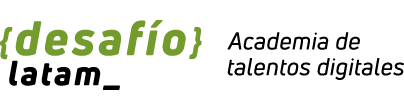


#<font color = 'green'>Reconocimiento de dígitos con red neuronal CNN</font>

Vamos a aplicar una red CNN al DataSet MNIST, para el reconocimiento de dígitos escritos a mano

### <font color = 'green'>Carga de librerías</font>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from skimage import io

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

from keras.models import Sequential
from keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from keras.constraints import MaxNorm
from keras.optimizers import SGD

### <font color = 'green'>Carga de datos</font>

In [ ]:
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, parser='auto')
X = X.values
y = y.astype(int).values

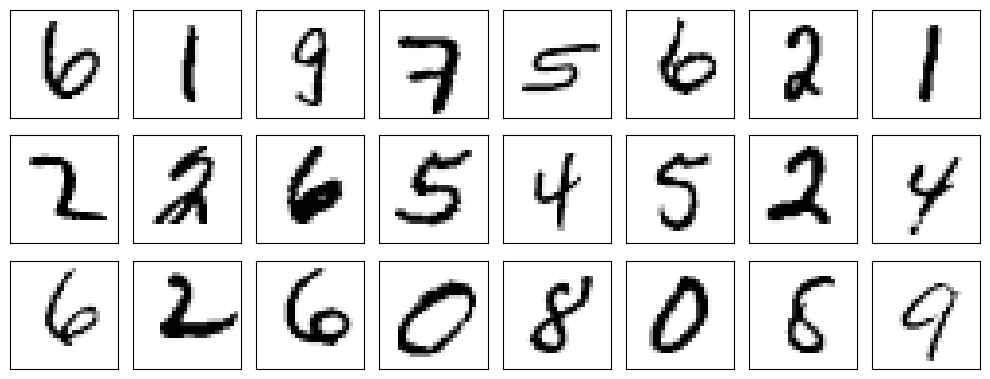

In [ ]:
nrows_ = 3
ncols_ = 8
fig, ax = plt.subplots(nrows=nrows_, ncols=ncols_, sharex=True, sharey=True, figsize=(10,4))

for i in range(nrows_):
    for j in range(ncols_):
        idx_rand_img = np.random.randint(0, X.shape[0]-1)
        img = X[idx_rand_img].reshape(28, 28)
        ax[i][j].imshow(img, cmap='Greys')

ax[0][0].set_xticks([])
ax[0][0].set_yticks([])
plt.tight_layout()
plt.show();

### <font color = 'green'>Escalar los valores de los píxels</font>

In [ ]:
X = X.reshape(X.shape[0], 28, 28)
X = X.astype('float32')/255.0
X.shape

(70000, 28, 28)

### <font color = 'green'>OneHotEncoder para target</font>

In [ ]:
y_ohe = OneHotEncoder(sparse_output=False).fit_transform(y.reshape(-1, 1))
y_ohe

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

### <font color = 'green'>Separación del conjunto de datos</font>

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_ohe, test_size=.33, random_state=23)

## <font color = 'green'>Implementación de la Red Neuronal Tipo AlexNet</font>

Aplicaremos ahora la Red Neuronal AlexNet, adecuada al problema de reconocimiento de dígitos escritos a mano.

In [ ]:
cnn_v1 = Sequential()

# Capa de entrada
cnn_v1.add(Input(shape=(X_train.shape[1], X_train.shape[2], 1)))

# Dos Capas Convolucional 32 3x3 1 1
cnn_v1.add(Conv2D(32, (3, 3), 1, 'same', activation='relu', kernel_initializer='he_normal'))

# Operación de Max Pooling 3x3 con stride 2
cnn_v1.add(MaxPooling2D((3, 3), 2))

cnn_v1.add(Flatten())

# Dos capas FC de 256 neuronas
cnn_v1.add(Dense(256, use_bias=True, activation='relu', kernel_initializer='he_normal'))

# Capa de salida
cnn_v1.add(Dense(10, use_bias=True, activation='softmax', kernel_initializer='glorot_normal'))

cnn_v1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn_v1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 5408)              0         
                                                                 
 dense (Dense)               (None, 256)               1384704   
                                                                 
 dense_1 (Dense)             (None, 10)                2570      
                                                                 
Total params: 1387594 (5.29 MB)
Trainable params: 1387594 (5.29 MB)
Non-trainable params: 0 (0.00 Byte)
__________________

Definida la red CNN, procedemos a entrenarla

In [ ]:
epochs = 10
hist_result = cnn_v1.fit(X_train, y_train, batch_size=32, epochs=epochs, validation_data=(X_test, y_test))
score = cnn_v1.evaluate(X_test, y_test, verbose=0)
print(f'\n\nTest accuracy: {score[1]}')

Epoch 1/10
1466/1466 [==============================] - 58s 39ms/step - loss: 0.1395 - accuracy: 0.9578 - val_loss: 0.0665 - val_accuracy: 0.9790
Epoch 2/10
1466/1466 [==============================] - 58s 39ms/step - loss: 0.0465 - accuracy: 0.9857 - val_loss: 0.0521 - val_accuracy: 0.9835
Epoch 3/10
1466/1466 [==============================] - 59s 40ms/step - loss: 0.0285 - accuracy: 0.9907 - val_loss: 0.0454 - val_accuracy: 0.9852
Epoch 4/10
1466/1466 [==============================] - 54s 37ms/step - loss: 0.0193 - accuracy: 0.9936 - val_loss: 0.0452 - val_accuracy: 0.9867
Epoch 5/10
1466/1466 [==============================] - 55s 38ms/step - loss: 0.0127 - accuracy: 0.9957 - val_loss: 0.0474 - val_accuracy: 0.9863
Epoch 6/10
1466/1466 [==============================] - 54s 37ms/step - loss: 0.0105 - accuracy: 0.9968 - val_loss: 0.0531 - val_accuracy: 0.9855
Epoch 7/10
1466/1466 [==============================] - 59s 40ms/step - loss: 0.0070 - accuracy: 0.9978 - val_loss: 0.0574 -

### <font color = 'green'>Predicciones sobre el conjunto de test y resultados</font>

Vamos a verificar nuestro modelo prediciendo algunas de las imágenes utilizadas.

722/722 [==============================] - 7s 10ms/step


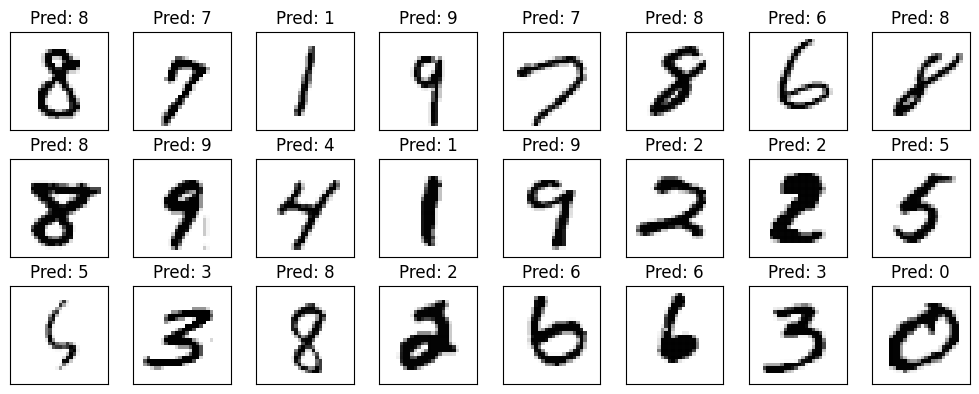

In [ ]:
yhat_test = cnn_v1.predict(X_test)
yhat_test = np.apply_along_axis(np.argmax, axis=1, arr=yhat_test)

nrows_ = 3
ncols_ = 8
fig, ax = plt.subplots(nrows=nrows_, ncols=ncols_, sharex=True, sharey=True, figsize=(10,4))

for i in range(nrows_):
    for j in range(ncols_):
        idx_rand_img = np.random.randint(0, X_test.shape[0]-1)
        img = X_test[idx_rand_img]
        ax[i][j].imshow(img, cmap='Greys')
        ax[i][j].set_title(f'Pred: {yhat_test[idx_rand_img]}')

ax[0][0].set_xticks([])
ax[0][0].set_yticks([])
plt.tight_layout()
plt.show();

### <font color = 'green'>Validación cruzada</font>

Utilizaremos ahora validación cruzada, con 5 fold para 5 epochs (Esto puede tomar varios minutos)

In [ ]:
epochs = 5
kfold = KFold(n_splits=5, shuffle=True)
accuracy_lst = []
hist_result = []
idx = 1

for itrain, itest in kfold.split(X.astype('float32')/255.0):
    X_train_, y_train_, X_test_, y_test_ = X[itrain], y_ohe[itrain], X[itest], y_ohe[itest]

    hist = cnn_v1.fit(X_train_, y_train_, batch_size=32, epochs=epochs, validation_data=(X_test_, y_test_), verbose=0)
    _, accuracy_ = cnn_v1.evaluate(X_test_, y_test_, verbose=0)

    print(f'[Fold, Accuracy]: [{idx}, {accuracy_}]')
    accuracy_lst.append(accuracy_)
    hist_result.append(hist)
    idx += 1

[Fold, Accuracy]: [1, 0.9937857389450073]
[Fold, Accuracy]: [2, 0.9962142705917358]
[Fold, Accuracy]: [3, 0.998285710811615]
[Fold, Accuracy]: [4, 0.9982143044471741]
[Fold, Accuracy]: [5, 0.9992142915725708]


Graficaremos ahora nuestros resultados

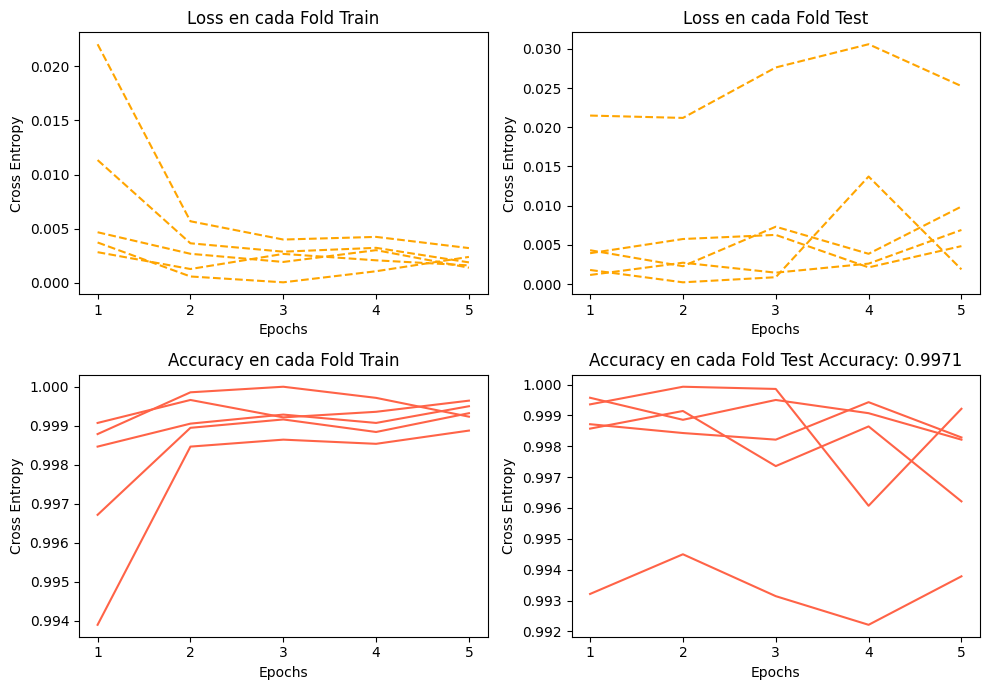

In [ ]:

plt.figure(figsize=(10, 7))
plt.subplot(2, 2, 1)
plt.title('Loss en cada Fold Train')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy')
plt.xticks(np.linspace(1, 5, 5, dtype=int))
for i in range(len(hist_result)):
    plt.plot(np.linspace(1, 5, 5), hist_result[i].history['loss'], color='orange', ls='--')


plt.subplot(2, 2, 3)
plt.title('Accuracy en cada Fold Train')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy')
plt.xticks(np.linspace(1, 5, 5, dtype=int))
for i in range(len(hist_result)):
    plt.plot(np.linspace(1, 5, 5), hist_result[i].history['accuracy'], color='tomato', ls='-')


plt.subplot(2, 2, 2)
plt.title('Loss en cada Fold Test')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy')
plt.xticks(np.linspace(1, 5, 5, dtype=int))
for i in range(len(hist_result)):
    plt.plot(np.linspace(1, 5, 5), hist_result[i].history['val_loss'], color='orange', ls='--')


plt.subplot(2, 2, 4)
plt.title(f'Accuracy en cada Fold Test Accuracy: {np.round(np.mean(accuracy_lst), 4)}')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy')
plt.xticks(np.linspace(1, 5, 5, dtype=int))
for i in range(len(hist_result)):
    plt.plot(np.linspace(1, 5, 5), hist_result[i].history['val_accuracy'], color='tomato', ls='-')



plt.tight_layout()
plt.show();